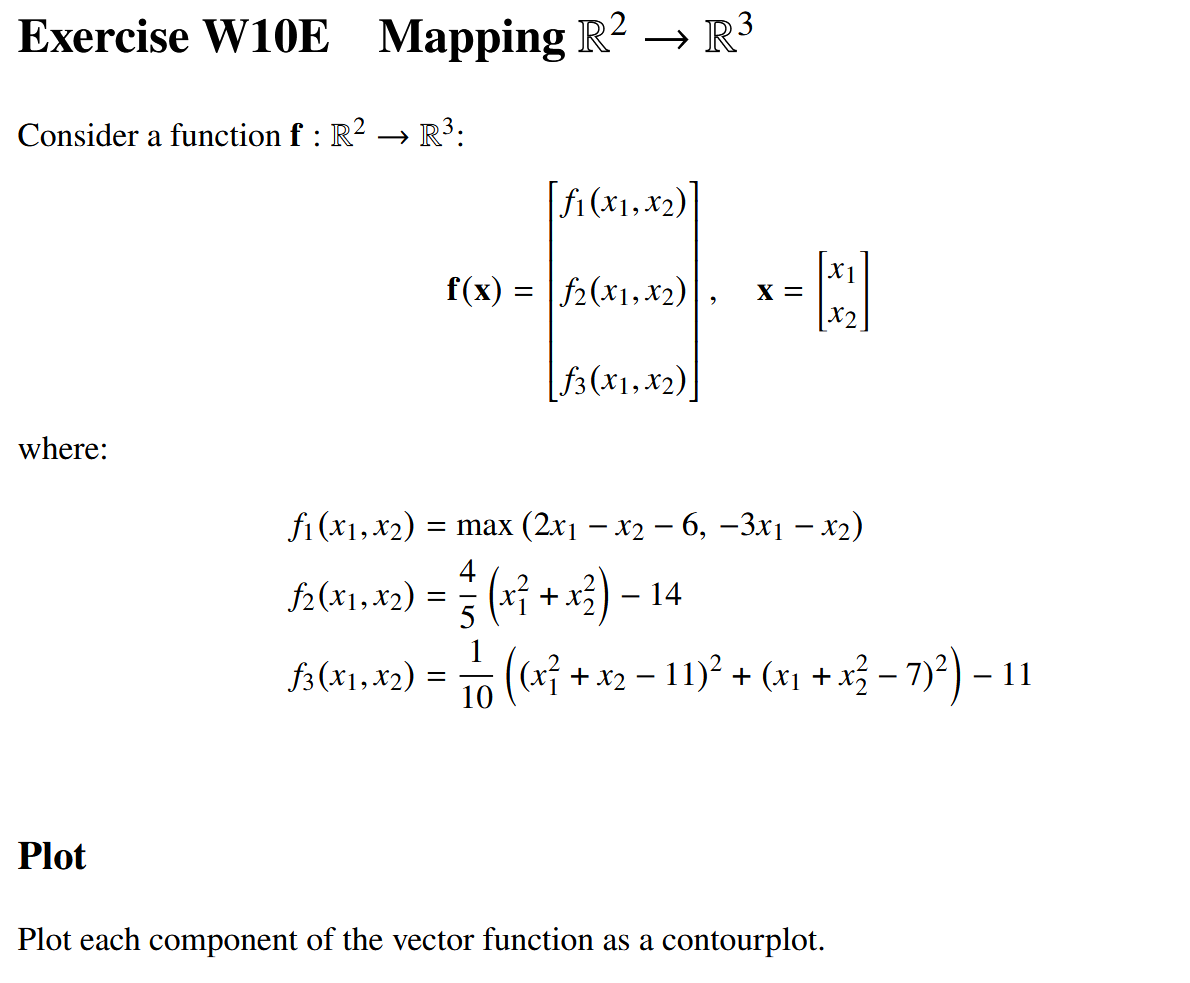

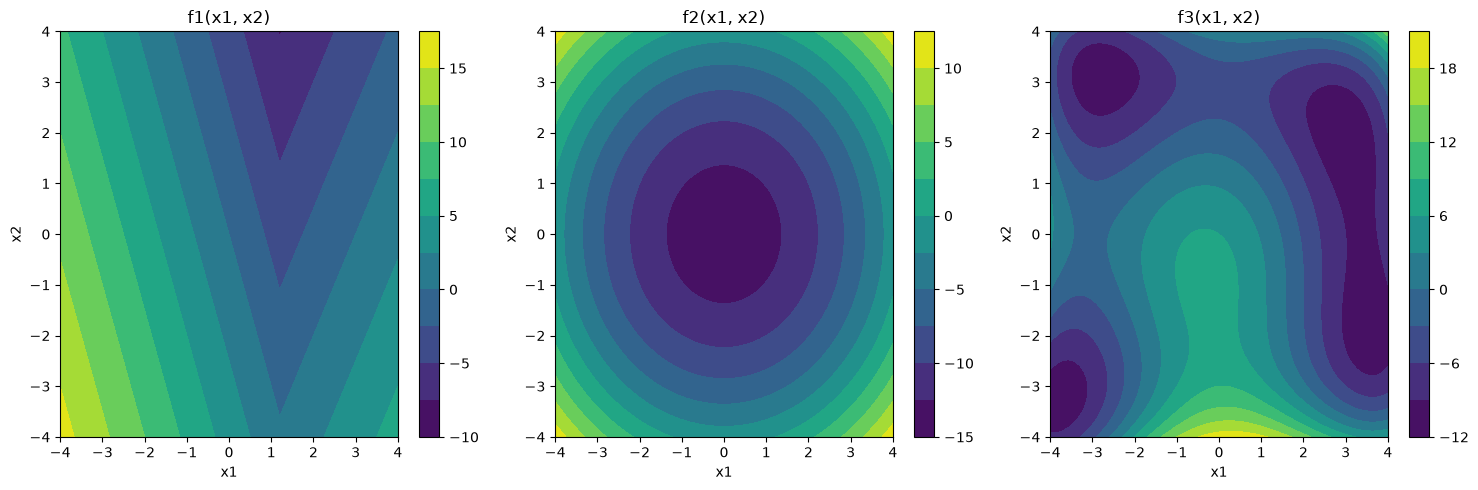

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

f1 = lambda x1, x2: np.maximum(2*x1 - x2 - 6, -3*x1 - x2)
f2 = lambda x1, x2: 0.8 * (x1**2 + x2**2) - 14
f3 = lambda x1, x2: 0.1 * ((x1**2 + x2 - 11)**2 + (x1 + x2**2 - 7)**2) - 11

x1_grid = np.linspace(-4, 4, 400)
x2_grid = np.linspace(-4, 4, 400)
X1, X2 = np.meshgrid(x1_grid, x2_grid)

Z1 = f1(X1, X2)
Z2 = f2(X1, X2)
Z3 = f3(X1, X2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

c1 = axes[0].contourf(X1, X2, Z1, levels=10, cmap='viridis')
fig.colorbar(c1, ax=axes[0])
axes[0].set_title('f1(x1, x2)')
axes[0].set_xlabel('x1')
axes[0].set_ylabel('x2')

c2 = axes[1].contourf(X1, X2, Z2, levels=10, cmap='viridis')
fig.colorbar(c2, ax=axes[1])
axes[1].set_title('f2(x1, x2)')
axes[1].set_xlabel('x1')
axes[1].set_ylabel('x2')

c3 = axes[2].contourf(X1, X2, Z3, levels=10, cmap='viridis')
fig.colorbar(c3, ax=axes[2])
axes[2].set_title('f3(x1, x2)')
axes[2].set_xlabel('x1')
axes[2].set_ylabel('x2')

plt.tight_layout()
plt.show()

N = 200
x = 8 * np.random.rand(N, 2) - 4
y1 = f1(*x.T)
y2 = f2(*x.T)
y3 = f3(*x.T)
y = np.array([y1, y2, y3]).T

X_tensor = torch.tensor(x, dtype=torch.float32)
Y_tensor = torch.tensor(y, dtype=torch.float32)

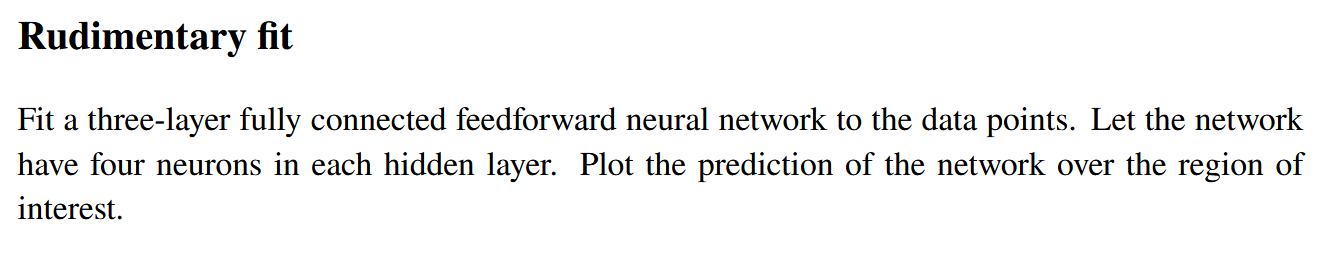

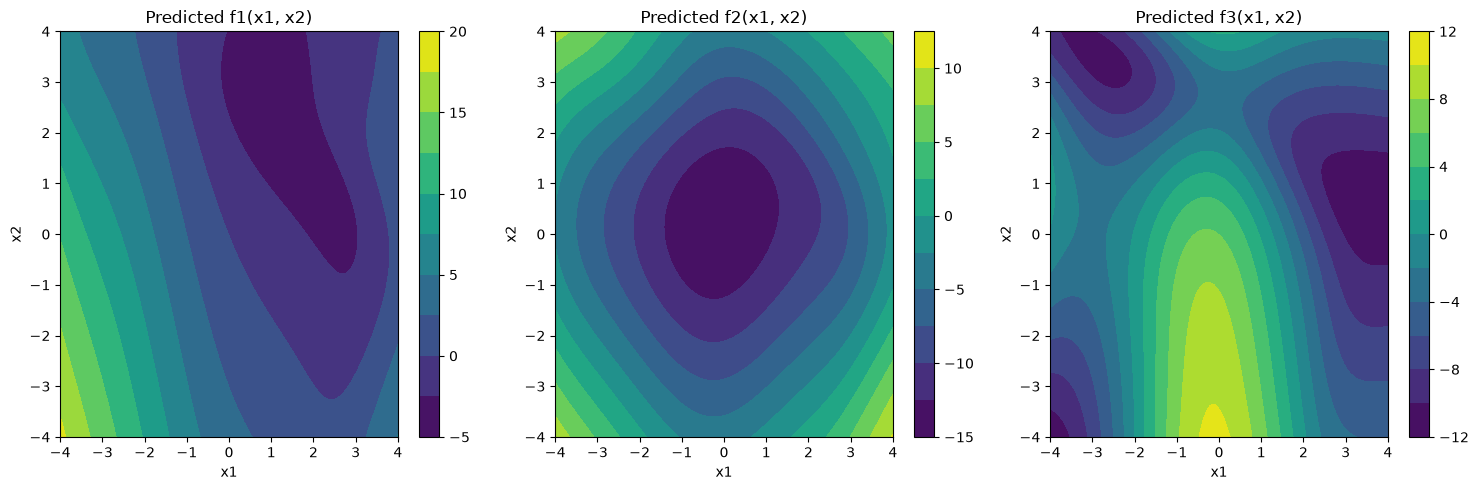

In [5]:
class R2toR3Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 4),
            nn.SiLU(),
            nn.Linear(4, 4),
            nn.SiLU(),
            nn.Linear(4, 3)
        )

    def forward(self, x):
        return self.net(x)

model = R2toR3Net()
optimizer = optim.Adam(model.parameters(), lr=1e-2)
loss_fn = nn.MSELoss()

for epoch in range(5000):
    optimizer.zero_grad()
    y_pred = model(X_tensor)
    loss = loss_fn(y_pred, Y_tensor)
    loss.backward()
    optimizer.step()

x1_grid = np.linspace(-4, 4, 100)
x2_grid = np.linspace(-4, 4, 100)
X1, X2 = np.meshgrid(x1_grid, x2_grid)

X_grid = np.stack([X1.flatten(), X2.flatten()], axis=1)
X_grid_tensor = torch.tensor(X_grid, dtype=torch.float32)

with torch.no_grad():
    Y_pred_tensor = model(X_grid_tensor)

Y_pred = Y_pred_tensor.numpy()
Z1_pred = Y_pred[:, 0].reshape(100, 100)
Z2_pred = Y_pred[:, 1].reshape(100, 100)
Z3_pred = Y_pred[:, 2].reshape(100, 100)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

c1 = axes[0].contourf(X1, X2, Z1_pred, levels=10, cmap='viridis')
fig.colorbar(c1, ax=axes[0])
axes[0].set_title('Predicted f1(x1, x2)')
axes[0].set_xlabel('x1')
axes[0].set_ylabel('x2')

c2 = axes[1].contourf(X1, X2, Z2_pred, levels=10, cmap='viridis')
fig.colorbar(c2, ax=axes[1])
axes[1].set_title('Predicted f2(x1, x2)')
axes[1].set_xlabel('x1')
axes[1].set_ylabel('x2')

c3 = axes[2].contourf(X1, X2, Z3_pred, levels=10, cmap='viridis')
fig.colorbar(c3, ax=axes[2])
axes[2].set_title('Predicted f3(x1, x2)')
axes[2].set_xlabel('x1')
axes[2].set_ylabel('x2')

plt.tight_layout()
plt.show()

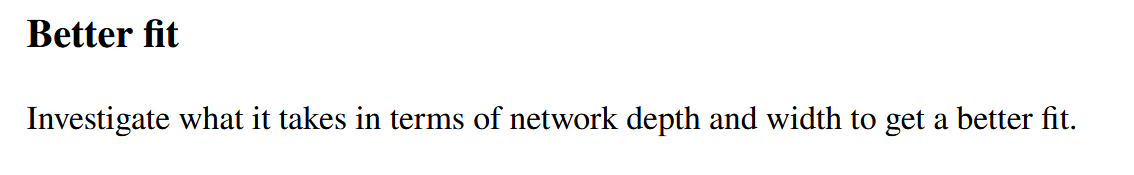

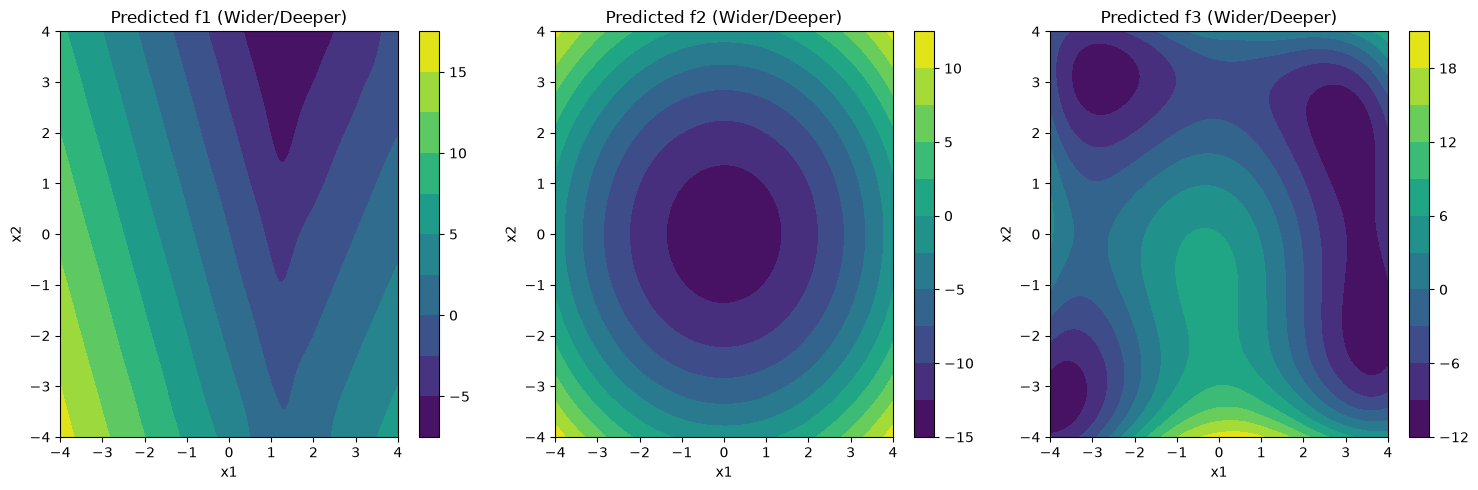

In [7]:
class ConfigurableNet(nn.Module):
    def __init__(self, hidden_dim=64, num_hidden_layers=4):
        super().__init__()
        layers = [nn.Linear(2, hidden_dim), nn.SiLU()]
        
        for _ in range(num_hidden_layers - 1):
            layers.extend([nn.Linear(hidden_dim, hidden_dim), nn.SiLU()])
            
        layers.append(nn.Linear(hidden_dim, 3))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

model = ConfigurableNet(hidden_dim=64, num_hidden_layers=4)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

for epoch in range(10000):
    optimizer.zero_grad()
    y_pred = model(X_tensor)
    loss = loss_fn(y_pred, Y_tensor)
    loss.backward()
    optimizer.step()

x1_grid = np.linspace(-4, 4, 100)
x2_grid = np.linspace(-4, 4, 100)
X1, X2 = np.meshgrid(x1_grid, x2_grid)

X_grid = np.stack([X1.flatten(), X2.flatten()], axis=1)
X_grid_tensor = torch.tensor(X_grid, dtype=torch.float32)

with torch.no_grad():
    Y_pred_tensor = model(X_grid_tensor)

Y_pred = Y_pred_tensor.numpy()
Z1_pred = Y_pred[:, 0].reshape(100, 100)
Z2_pred = Y_pred[:, 1].reshape(100, 100)
Z3_pred = Y_pred[:, 2].reshape(100, 100)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

c1 = axes[0].contourf(X1, X2, Z1_pred, levels=10, cmap='viridis')
fig.colorbar(c1, ax=axes[0])
axes[0].set_title('Predicted f1 (Wider/Deeper)')
axes[0].set_xlabel('x1')
axes[0].set_ylabel('x2')

c2 = axes[1].contourf(X1, X2, Z2_pred, levels=10, cmap='viridis')
fig.colorbar(c2, ax=axes[1])
axes[1].set_title('Predicted f2 (Wider/Deeper)')
axes[1].set_xlabel('x1')
axes[1].set_ylabel('x2')

c3 = axes[2].contourf(X1, X2, Z3_pred, levels=10, cmap='viridis')
fig.colorbar(c3, ax=axes[2])
axes[2].set_title('Predicted f3 (Wider/Deeper)')
axes[2].set_xlabel('x1')
axes[2].set_ylabel('x2')

plt.tight_layout()
plt.show()

To investigate what it takes in terms of network depth and width to get a better fit, you must significantly increase the capacity of the model beyond the rudimentary $2 \rightarrow 4 \rightarrow 4 \rightarrow 3$ architecture.

* **Width:** Increasing the width (e.g., from 4 to 64 neurons per layer) provides the mathematical flexibility required to map the high-frequency features in the data, such as the sharp linear intersection in $f_1$ and the complex elliptical valleys in $f_3$. A width of 4 severely bottlenecks the information, forcing the network to output overly smoothed, inaccurate shapes.
* **Depth:** Increasing the depth (e.g., expanding to 4 hidden layers) allows the network to compose multiple non-linear `SiLU` transformations. This is crucial for hierarchical feature learning, enabling the model to bend and distort the 2D input coordinate space sequentially until it perfectly matches the complex 3D topology of the target functions.

By expanding the architecture to $2 \rightarrow 64 \rightarrow 64 \rightarrow 64 \rightarrow 64 \rightarrow 3$ and training for more epochs (e.g., $10000$), the network overcomes the previous underfitting constraints. The resulting contour plots will transition from vague blobs into crisp reconstructions that closely mirror the exact mathematical target plots generated earlier in the exercise.